# Statistical modeling of cholesterol (SAS)

The code is the same as `Cholesterol_code.sas`, cut into sections. The results shown under the cells are taken from the report, not from a fresh run: charts are the images from the report and tables are copied from it. Only results I could match to a specific step are shown. The data is simulated and is not included here.

## Import and clean the data

In [ ]:
data SOR3004.CAD;
    infile "/home/u64128910/SOR3004/newCAD_2.csv" dsd firstobs=2 dlm=',' missover;
    input 
        Cholesterol 
        steps 
        CAD
        sbp 
        dbp 
        age 
        bmi 
        gender 
        exercise 
        takeaway 
        ;
run;

data SOR3004.CAD_clean;
    set SOR3004.CAD;
    if _n_ not in (10, 11, 12, 136);
run;

## Summary statistics

In [ ]:
proc means data=SOR3004.CAD_clean mean std median min max n;
   var Cholesterol steps sbp dbp age bmi exercise;
run;

Variable      Mean      Std Dev   Median    Minimum   Maximum
Cholesterol   8753.29   3486.15   8881.77   874.68    18013.51
Steps         5401.77   2114.16   5415.00   693.00    10956.00
SBP           132.84    24.41     134.00    49.00     206.00
DBP           80.04     26.44     79.00     12.00     160.00
Age           58.98     9.13      59.03     31.00     82.00
BMI           25.07     4.77      25.00     10.00     39.00
Exercise      303.60    224.20    265.33    2.24      1112.19


## Plots

In [ ]:
proc sgplot data=SOR3004.CAD;
   histogram age / binwidth=1;
   xaxis label="Age";
   yaxis label="Frequency";
run;

proc sgplot data=SOR3004.CAD;
    scatter x=steps y=cholesterol;
    title "Scatter Plot: Steps vs Cholesterol";
    xaxis label="Daily Steps";
    yaxis label="Cholesterol Level";
run;

proc sgplot data=SOR3004.CAD;
    scatter x=exercise y=cholesterol;
    title "Scatter Plot: Exercise vs Cholesterol";
    xaxis label="Exercise";
    yaxis label="Cholesterol Level";
run;

proc sgplot data=SOR3004.CAD;
    scatter x=age y=cholesterol;
    title "Scatter Plot: age vs Cholesterol";
    xaxis label="age";
    yaxis label="Cholesterol Level";
run;

proc sgplot data=SOR3004.CAD;
    scatter x=sbp y=cholesterol;
    title "Scatter Plot: sbp vs Cholesterol";
    xaxis label="sbp";
    yaxis label="Cholesterol Level";
run;

proc sgplot data=SOR3004.CAD;
    scatter x=bmi y=cholesterol;
    title "Scatter Plot: bmi vs Cholesterol";
    xaxis label="bmi";
    yaxis label="Cholesterol Level";
run;

proc sgplot data=SOR3004.CAD;
    scatter x=dbp y=cholesterol;
    title "Scatter Plot: dbp vs Cholesterol";
    xaxis label="dbp";
    yaxis label="Cholesterol Level";
run;


proc sgplot data=SOR3004.CAD;
    scatter x=bmi y=Cholesterol;
    reg x=bmi y=Cholesterol;
    title "Cholesterol vs BMI with Regression Line";
run;


proc sgplot data=SOR3004.CAD;
   histogram age / binwidth=1; 
   xaxis label="Age";
   yaxis label="Frequency";
run;

## Correlations

In [ ]:
proc corr data=SOR3004.CAD;
   var Cholesterol steps sbp dbp age bmi exercise takeaway;
   title "Correlation Analysis of Continuous Variables";
run;

## Gender recode and frequency tables

In [ ]:
data SOR3004.CAD_cleanv1;
    set SOR3004.CAD_clean;
    length gender1 $8;
    if gender = 1 then gender1 = 'male';
    else if gender = 0 then gender1 = 'female';
    else gender1 = .;
run;

proc freq data=SOR3004.CAD_cleanv1;
   tables CAD gender1 takeaway;
run;

proc means data=SOR3004.CAD_cleanv1;
    class gender1;
    var Cholesterol;
    output out=Cholesterol_rates_gender mean=ovr_Cholesterol_mean n=count;
run;

## Cholesterol by gender

In [ ]:
proc sgplot data=Cholesterol_rates_gender;
    vbar gender1 / response=ovr_Cholesterol_mean;
    xaxis label="Gender";
    yaxis label="Average Cholesterol Level";
    title "Average Cholesterol Level by Gender"; 
run;

proc means data=SOR3004.CAD_cleanv1;
    class cad;
    var Cholesterol;
    output out=Cholesterol_rates_cad mean=ovr_Cholesterol_mean n=count;
run;

proc sgplot data=SOR3004.CAD_cleanv1;
    vbar cad / response=Cholesterol stat=mean;
    xaxis label="CAD Status";
    yaxis label="Average Cholesterol Level";
    title "Average Cholesterol Level by CAD Status";
run;

## Variable selection

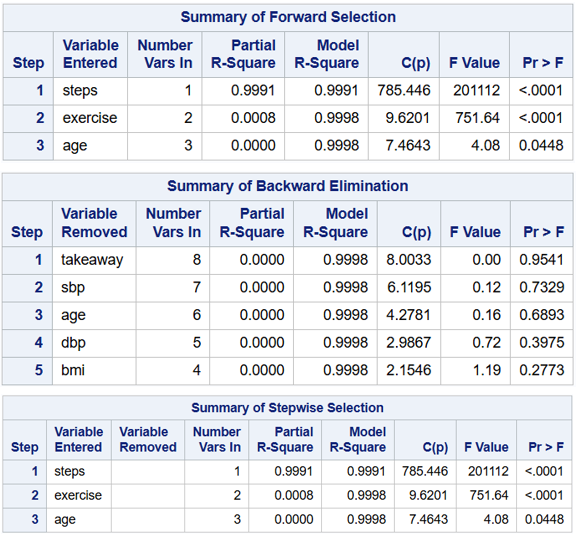

In [ ]:
/* Forward Selection*/
proc reg data=SOR3004.CAD_cleanv1;
    model Cholesterol = steps sbp dbp age bmi exercise takeaway gender / 
          selection=forward slentry=0.10;
    title "Forward Selection with All Predictors (slentry=0.10)";
run;

/* Backward Selection*/
proc reg data=SOR3004.CAD_cleanv1;
    model Cholesterol = steps sbp dbp age bmi exercise takeaway gender / 
          selection=backward slstay=0.10;
    title "Backward Selection with All Predictors (slstay=0.10)";
run;

/* Stepwise Selection*/
proc reg data=SOR3004.CAD_cleanv1;
    model Cholesterol = steps sbp dbp age bmi exercise takeaway gender / 
          selection=stepwise slentry=0.10 slstay=0.10;
    title "Stepwise Selection with All Predictors (slentry=0.10, slstay=0.10)";
run;

## Regression diagnostics

In [ ]:
proc reg data=SOR3004.CAD_cleanv1;
    model Cholesterol = steps sbp dbp age bmi exercise takeaway gender / influence;
    output out=CAD_diagnostics residual=residual student=r rstudent=t 
           cookd=cookd press=press;
    plot residual.*predicted.;
    plot student.*predicted.;
    plot rstudent.*predicted.;
    plot student.*qqplot;
    title "Regression Diagnostics with All Predictors";
run;

proc print data=CAD_diagnostics;
    var Cholesterol steps sbp dbp age bmi exercise takeaway gender 
        residual r t cookd press;
    title "Diagnostic Statistics for Each Observation";
run;

## Gender and age interaction

In [ ]:
data SOR3004.CAD_interaction;
    set SOR3004.CAD_cleanv1;
    gender_age = gender * age; 
run;


proc reg data=SOR3004.CAD_interaction;
    model Cholesterol = steps age exercise gender gender_age;
    title "Formal Test: Does Gender Modify Age Effect on Cholesterol?";
run;

## Box-Tidwell transformation

In [ ]:
*Box-Tidwell;
proc iml;
reset noprint;
use SOR3004.CAD_cleanv1;
read all var{age steps exercise} into x1; 
read all var{Cholesterol} into y;
int=j(nrow(x1),1,1);
alphacurrent=j(ncol(x1),1,1);    /* Now 3x1 instead of 2x1 */
x=int||x1;
firstbeta=inv(t(x)*x)*t(x)*y;
z1=x1#log(x1);
w=x1;
do i=1 to 5;
x=int||w||z1;
beta = inv(t(x)*x)*t(x)*y;
alphanew=((beta[4:6]/firstbeta[2:4])+1)#alphacurrent[1:3];
w=x1[,1]##alphanew[1]||x1[,2]##alphanew[2]||x1[,3]##alphanew[3];
x=int||w;
firstbeta = inv(t(x)*x)*t(x)*y;
z1 = w#log(w);
alphacurrent=alphanew;
print(alphacurrent);
end;
quit;

## Transformed regression

In [ ]:
data SOR3004.CAD_transformed;
set SOR3004.CAD_cleanv1; 
newsteps = steps**0.217;
newexercise = exercise**1.009;
newage = age**1.892;
run;

proc reg data=SOR3004.CAD_transformed;
model Cholesterol = newsteps newexercise newage / influence;
plot rstudent * predicted.;
run;

## Principal components and VIF

In [ ]:
proc princomp data=SOR3004.CAD_cleanv1;
var newsteps newage newexercise;
run;

*VIF and colinearity;
proc reg data=SOR3004.CAD_cleanv1;
model Cholesterol = newsteps newage newexercise / vif collinoint corrb;
run;